# 03 — Cell Clustering
**Inputs**: `adata/adata_all_qc.h5ad`  
**Outputs**: `adata/adata_all_hvg_umap.h5ad`, `adata/adata_hi4_hvg_geve_umap.h5ad` (the latter deposited on Zenodo)  
**Figures**: `upstream/figures/`

## Steps
### All-cells (§ 3.1)
1. Normalize + log1p
2. HVG(2,000) + all 528 GEVE genes forced
3. PCA 50 comps → neighbors (nn=15, 30 PCs) → UMAP (min_dist=0.4, spread=1.5) → Leiden res=0.3
4. Save `adata_all_hvg_umap.h5ad`

### GEVE>4 sub-clustering (§ 3.2 – 3.5)
5. Subset GEVE>4 cells (n≈4,688)
6. HVG(1,500) + all 528 GEVE genes forced → PCA 50 comps
7. Neighbors (nn=10, 30 PCs) → UMAP (min_dist=0.5, spread=2.0) → Leiden res=0.4 → merge to 4 clusters
8. AGO gene expression on UMAP (§ 3.3)
9. Doublet score inspection (§ 3.4)
10. Sample/DPI batch assessment (§ 3.5)
11. Save `adata_hi4_hvg_geve_umap.h5ad`

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.colors as mcolors
import gc
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path

import os
BASE      = Path.cwd().parent                                   # repository root (run from upstream/)
ADATA_DIR = Path(os.environ.get('GEVE_ADATA_DIR', BASE / 'adata'))
FIG_DIR   = BASE / 'upstream' / 'figures'
FIG_DIR.mkdir(exist_ok=True)

# ── BVP/DVP annotation helper ─────────────────────────────────────────────────
excel_path = BASE / 'data' / 'Chlamy_GEVE_gene_annotation.xlsx'
df_ano = pd.read_excel(excel_path, sheet_name='GEVEv2_full_ano', engine='openpyxl')
gene_to_cluster = {row['gene']: row['cluster']
                   for _, row in df_ano.iterrows() if pd.notna(row['cluster'])}
print("BVP/DVP annotation loaded:", len(gene_to_cluster), "genes")

BVP/DVP annotation loaded: 181 genes


## Figure 3.1 — All-cells UMAP

UMAP of all 28,645 QC-filtered cells.  
Features: HVG(2,000) + all 528 GEVE genes forced (Seurat flavor).  
PCA 50 comps → neighbors nn=15, 30 PCs → UMAP min_dist=0.4 spread=1.5 → Leiden res=0.3.

Panels: (A) Leiden cluster, (B) log1p(GEVE UMIs), (C) DPI.  
MCP+ cells shown with bold black border across all panels.

**Source**: `upstream/03_clustering.ipynb`  
**File**: `upstream/figures/all_cells_umap.png`

In [2]:
# ── Load & normalise ──────────────────────────────────────────────────────────
adata_all = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
sc.pp.normalize_total(adata_all, target_sum=1e4)
sc.pp.log1p(adata_all)

adata_all.var['cluster'] = [gene_to_cluster.get(v.split('_cr2937r')[0], '')
                             for v in adata_all.var_names]

# ── HVG(2000) + all GEVE forced ───────────────────────────────────────────────
sc.pp.highly_variable_genes(adata_all, n_top_genes=2000, flavor='seurat',
                             min_mean=0.01, max_mean=10, min_disp=0.3)
adata_all.var.loc[adata_all.var['gene_type'] == 'GEVE', 'highly_variable'] = True
sc.pp.scale(adata_all, max_value=10)
sc.tl.pca(adata_all, n_comps=50, mask_var=adata_all.var['highly_variable'])

for k in list(adata_all.uns.get('pca', {}).get('params', {}).keys()):
    if hasattr(adata_all.uns['pca']['params'][k], 'index'):
        del adata_all.uns['pca']['params'][k]

# ── Neighbors → UMAP → Leiden ─────────────────────────────────────────────────
sc.pp.neighbors(adata_all, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_all, min_dist=0.4, spread=1.5)
sc.tl.leiden(adata_all, resolution=0.3, key_added='leiden_all')

# ── Save ──────────────────────────────────────────────────────────────────────
adata_all.write_h5ad(ADATA_DIR / 'adata_all_hvg_umap.h5ad')

# ── Stash UMAP coordinates + obs for plotting ─────────────────────────────────
umap_all   = adata_all.obsm['X_umap'].copy()
obs_all    = adata_all.obs.copy()
mcp_all    = obs_all['mcp_raw'].values > 0
geve_log_all = np.log1p(obs_all['geve_raw'].values)

print("All-cells UMAP done. Shape:", adata_all.shape)
print("Leiden clusters:", obs_all['leiden_all'].value_counts().to_dict())

All-cells UMAP done. Shape: (22421, 15036)
Leiden clusters: {'0': 16668, '1': 5726, '2': 27}


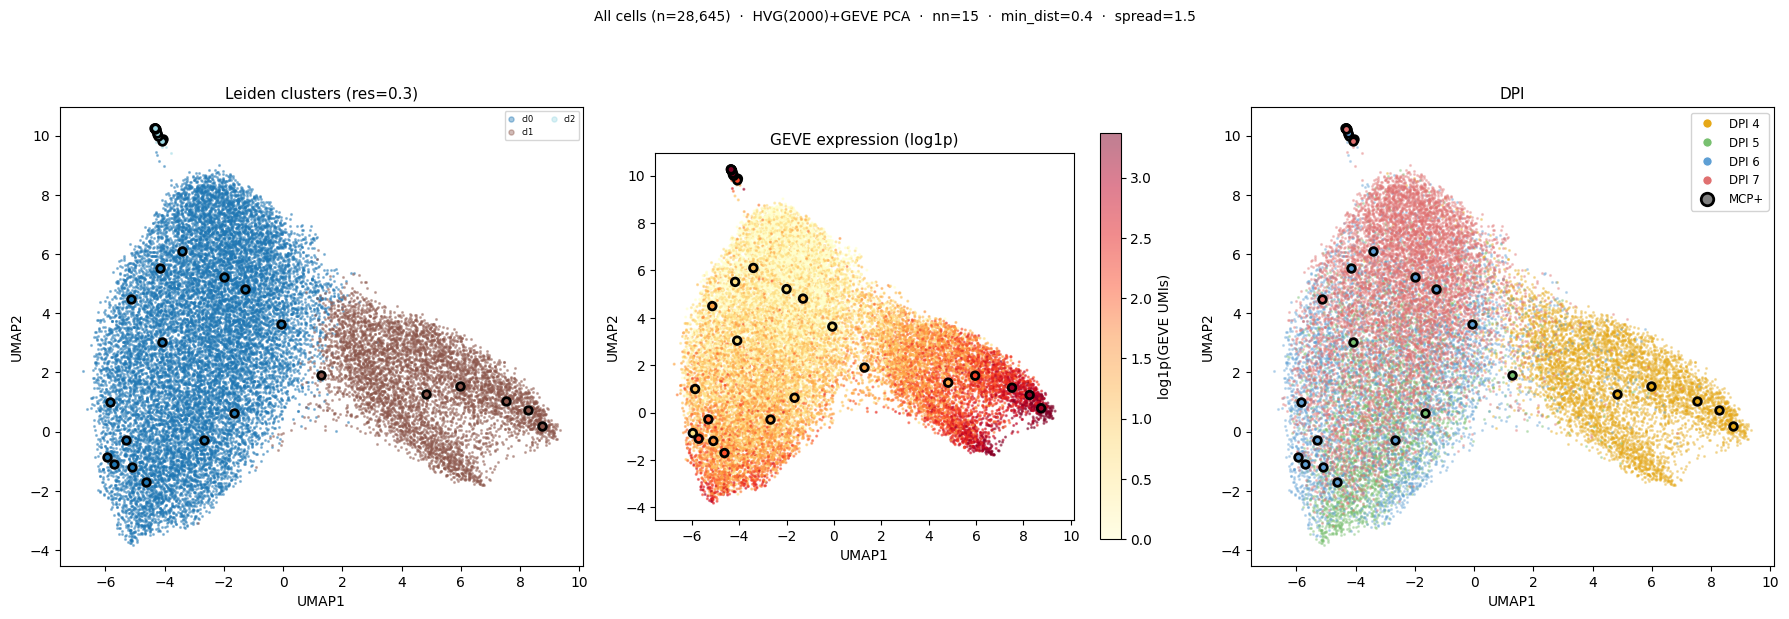

Cells per DPI:
dpi
4    5614
5    3810
6    4539
7    8458
Name: count, dtype: int64


In [3]:
DPI_COLORS   = {4: '#e6a817', 5: '#78c070', 6: '#5e9fd4', 7: '#e07070'}
MCP_LW, MCP_S = 2.0, 30
leiden_cats = sorted(obs_all['leiden_all'].unique(), key=lambda x: int(x))
N_cl = len(leiden_cats)
palette = plt.cm.tab20(np.linspace(0, 1, N_cl))
CL_COLORS = {cl: palette[i] for i, cl in enumerate(leiden_cats)}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Panel A — Leiden clusters
ax = axes[0]
for cl in leiden_cats:
    m = (obs_all['leiden_all'] == cl).values
    ax.scatter(umap_all[m,0], umap_all[m,1], s=1.5, alpha=0.4,
               color=CL_COLORS[cl], rasterized=True, label=f'cl{cl}')
for cl in leiden_cats:
    m = (obs_all['leiden_all'] == cl).values & mcp_all
    if m.sum():
        ax.scatter(umap_all[m,0], umap_all[m,1], s=MCP_S, alpha=1.0,
                   facecolors=CL_COLORS[cl], edgecolors='black',
                   linewidths=MCP_LW, zorder=8, rasterized=False)
ax.legend(fontsize=6, loc='best', framealpha=0.8, markerscale=3,
          ncol=2, handlelength=0.8)
ax.set_title('Leiden clusters (res=0.3)', fontsize=11)
ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2'); ax.set_aspect('equal')

# Panel B — GEVE expression
ax = axes[1]
vmax = np.percentile(geve_log_all[geve_log_all > 0], 99) if (geve_log_all > 0).any() else 1
norm_g = mcolors.Normalize(vmin=0, vmax=vmax)
cmap_g = plt.cm.YlOrRd
sc_g = ax.scatter(umap_all[:,0], umap_all[:,1], s=1.5,
                   c=geve_log_all, cmap=cmap_g, norm=norm_g,
                   alpha=0.5, rasterized=True)
mcp_fc = cmap_g(norm_g(geve_log_all[mcp_all]))
ax.scatter(umap_all[mcp_all,0], umap_all[mcp_all,1], s=MCP_S, alpha=1.0,
           facecolors=mcp_fc, edgecolors='black',
           linewidths=MCP_LW, zorder=8, rasterized=False)
plt.colorbar(sc_g, ax=ax, label='log1p(GEVE UMIs)', shrink=0.75)
ax.set_title('GEVE expression (log1p)', fontsize=11)
ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2'); ax.set_aspect('equal')

# Panel C — DPI
ax = axes[2]
for dpi in [4, 5, 6, 7]:
    m = (obs_all['dpi'] == dpi).values
    ax.scatter(umap_all[m,0], umap_all[m,1], s=1.5, alpha=0.3,
               color=DPI_COLORS[dpi], rasterized=True, label=f'DPI {dpi}')
for dpi in [4, 5, 6, 7]:
    m = (obs_all['dpi'] == dpi).values & mcp_all
    if m.sum():
        ax.scatter(umap_all[m,0], umap_all[m,1], s=MCP_S, alpha=1.0,
                   facecolors=DPI_COLORS[dpi], edgecolors='black',
                   linewidths=MCP_LW, zorder=8, rasterized=False)
handles = [mlines.Line2D([], [], marker='o', color='w',
           markerfacecolor=DPI_COLORS[d], markersize=7, label=f'DPI {d}')
           for d in [4,5,6,7]]
handles.append(mlines.Line2D([], [], marker='o', color='w',
               markerfacecolor='grey', markeredgecolor='black',
               markeredgewidth=MCP_LW, markersize=9, label='MCP+'))
ax.legend(handles=handles, fontsize=8.5, loc='best', framealpha=0.85)
ax.set_title('DPI', fontsize=11)
ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2'); ax.set_aspect('equal')

plt.suptitle('All cells (n=28,645)  ·  HVG(2000)+GEVE PCA  ·  nn=15  ·  min_dist=0.4  ·  spread=1.5',
             fontsize=10, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'all_cells_umap.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'all_cells_umap.pdf', bbox_inches='tight')
plt.show()
print(f"Cells per DPI:\n{obs_all['dpi'].value_counts().sort_index()}")

In [4]:
del adata_all
gc.collect()
print("All-cells adata freed.")

All-cells adata freed.


## Figure 3.2 — GEVE>4 clustering (3-panel UMAP)

UMAP of GEVE>4 cells (n≈4,688). Features: HVG(1,500) + all 528 GEVE genes forced.  
PCA 50 comps → nn=10, 30 PCs → UMAP (min_dist=0.5, spread=2.0) → Leiden res=0.4.

**4 clusters** (3 DPI4 Leiden clusters merged to 2):

| Cluster | n | MCP+ | %DPI4 | med GEVE | max GEVE |
|---------|---|------|-------|----------|----------|
| DPI4-A  | 2,150 | 6  | 97%  | 9       | 81      |
| DPI4-B  | 1,336 | 0  | 98%  | 9       | 41      |
| DPI5-7  | 1,181 | 3  | 1%   | 6       | 21      |
| **Lytic** | **21** | **14** | 10% | **65** | **242** |

MCP+ cells shown as bold-bordered dots coloured by their panel (cluster / GEVE expression / DPI).  
Saved: `adata/adata_hi4_hvg_geve_umap.h5ad` with `obs['cluster_hi4']`.

**Source**: `upstream/03_clustering.ipynb`  
**File**: `upstream/figures/geve_hi4_clustering_v5.png`

In [ ]:
# ── Reload QC adata, normalise, attach annotation ─────────────────────────────
adata = sc.read_h5ad(ADATA_DIR / 'adata_all_qc.h5ad')
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

adata.var['cluster'] = [gene_to_cluster.get(v.split('_cr2937r')[0], '')
                        for v in adata.var_names]

# ── Subset GEVE>4, build HVG(1500)+GEVE combined PCA ─────────────────────────
adata_hi = adata[adata.obs['geve_hi4']].copy()
del adata; gc.collect()

sc.pp.highly_variable_genes(adata_hi, n_top_genes=1500, flavor='seurat',
                             min_mean=0.01, max_mean=10, min_disp=0.3)
adata_hi.var.loc[adata_hi.var['gene_type'] == 'GEVE', 'highly_variable'] = True

sc.pp.scale(adata_hi, max_value=10)
sc.tl.pca(adata_hi, n_comps=50, mask_var=adata_hi.var['highly_variable'])

for k in list(adata_hi.uns.get('pca', {}).get('params', {}).keys()):
    if hasattr(adata_hi.uns['pca']['params'][k], 'index'):
        del adata_hi.uns['pca']['params'][k]

# ── Graph → UMAP → Leiden → merge clusters ───────────────────────────────────
sc.pp.neighbors(adata_hi, n_neighbors=10, n_pcs=30)
sc.tl.umap(adata_hi, min_dist=0.5, spread=2.0)
sc.tl.leiden(adata_hi, resolution=0.4, key_added='leiden_0p4')

label_map = {'0': 'DPI4-A', '1': 'DPI4-B', '3': 'DPI4-A', '2': 'DPI5-7', '4': 'Lytic'}
adata_hi.obs['cluster_hi4'] = adata_hi.obs['leiden_0p4'].map(label_map).astype('category')

# ── Save ──────────────────────────────────────────────────────────────────────
adata_hi.write_h5ad(ADATA_DIR / 'adata_hi4_hvg_geve_umap.h5ad')

# ── Stash for downstream plots (§3.2–3.5) ────────────────────────────────────
umap_hi  = adata_hi.obsm['X_umap'].copy()
obs_hi   = adata_hi.obs.copy()
mcp_hi   = obs_hi['mcp_raw'].values > 0

print("GEVE>4 clustering done. Shape:", adata_hi.shape)
print(adata_hi.obs['cluster_hi4'].value_counts())

In [ ]:
CLUSTER_ORDER = ['DPI4-A', 'DPI4-B', 'DPI5-7', 'Lytic']
CMAP     = {'DPI4-A': '#e6a817', 'DPI4-B': '#f5d640', 'DPI5-7': '#5b9ec9', 'Lytic': '#c0392b'}
DPI_CMAP = {4: '#e6a817', 5: '#78c070', 6: '#5e9fd4', 7: '#e07070'}
MCP_LW, MCP_S = 2.0, 40

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))

# Panel A — cluster labels
ax = axes[0]
zorder_map = {'DPI4-A': 1, 'DPI4-B': 1, 'DPI5-7': 2, 'Lytic': 4}
for cl in CLUSTER_ORDER:
    m = (obs_hi['cluster_hi4'] == cl).values
    ax.scatter(umap_hi[m,0], umap_hi[m,1], s=4, alpha=0.5,
               color=CMAP[cl], rasterized=True, zorder=zorder_map[cl])
for cl in CLUSTER_ORDER:
    m = (obs_hi['cluster_hi4'] == cl).values & mcp_hi
    if m.sum():
        ax.scatter(umap_hi[m,0], umap_hi[m,1], s=MCP_S, alpha=1.0,
                   facecolors=CMAP[cl], edgecolors='black', linewidths=MCP_LW,
                   zorder=8, rasterized=False)
handles = [mpatches.Patch(color=CMAP[cl], label=cl) for cl in CLUSTER_ORDER]
handles.append(mlines.Line2D([], [], marker='o', color='w',
               markerfacecolor='grey', markeredgecolor='black',
               markeredgewidth=MCP_LW, markersize=9, label='MCP+'))
ax.legend(handles=handles, fontsize=8.5, loc='best', framealpha=0.85)
ax.set_title('Clusters', fontsize=12)
ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2'); ax.set_aspect('equal')

# Panel B — GEVE expression
ax = axes[1]
geve_log_hi = np.log1p(obs_hi['geve_raw'].values)
vmax = np.percentile(geve_log_hi, 99)
norm_g = mcolors.Normalize(vmin=0, vmax=vmax)
cmap_g = plt.cm.YlOrRd
sc_g = ax.scatter(umap_hi[:,0], umap_hi[:,1], s=4, c=geve_log_hi,
                   cmap=cmap_g, norm=norm_g, alpha=0.7, rasterized=True)
mcp_fc = cmap_g(norm_g(geve_log_hi[mcp_hi]))
ax.scatter(umap_hi[mcp_hi,0], umap_hi[mcp_hi,1], s=MCP_S, alpha=1.0,
           facecolors=mcp_fc, edgecolors='black', linewidths=MCP_LW,
           zorder=8, rasterized=False)
plt.colorbar(sc_g, ax=ax, label='log1p(GEVE UMIs)', shrink=0.75)
mcp_h = mlines.Line2D([], [], marker='o', color='w', markerfacecolor='#d62728',
                       markeredgecolor='black', markeredgewidth=MCP_LW,
                       markersize=9, label='MCP+')
ax.legend(handles=[mcp_h], fontsize=8.5, loc='lower right', framealpha=0.85)
ax.set_title('GEVE expression (log1p)', fontsize=12)
ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2'); ax.set_aspect('equal')

# Panel C — DPI
ax = axes[2]
for dpi in [4, 5, 6, 7]:
    m = (obs_hi['dpi'] == dpi).values
    ax.scatter(umap_hi[m,0], umap_hi[m,1], s=4, alpha=0.4,
               color=DPI_CMAP[dpi], rasterized=True, zorder=1)
for dpi in [4, 5, 6, 7]:
    m = (obs_hi['dpi'] == dpi).values & mcp_hi
    if m.sum():
        ax.scatter(umap_hi[m,0], umap_hi[m,1], s=MCP_S, alpha=1.0,
                   facecolors=DPI_CMAP[dpi], edgecolors='black', linewidths=MCP_LW,
                   zorder=8, rasterized=False)
dpi_handles = [mlines.Line2D([], [], marker='o', color='w',
               markerfacecolor=DPI_CMAP[d], markersize=7, label=f'DPI {d}')
               for d in [4,5,6,7]]
dpi_handles.append(mlines.Line2D([], [], marker='o', color='w',
                    markerfacecolor='grey', markeredgecolor='black',
                    markeredgewidth=MCP_LW, markersize=9, label='MCP+'))
ax.legend(handles=dpi_handles, fontsize=8.5, loc='best', framealpha=0.85)
ax.set_title('DPI', fontsize=12)
ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2'); ax.set_aspect('equal')

plt.suptitle('GEVE>4 cells  ·  HVG(1500)+GEVE PCA  ·  nn=10  ·  min_dist=0.5  ·  spread=2.0',
             fontsize=10, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / 'geve_hi4_clustering_v5.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'geve_hi4_clustering_v5.pdf', bbox_inches='tight')
plt.show()

## Figure 3.3 — AGO gene expression on GEVE>4 UMAP

AGO (Argonaute) genes are key PTGS/RNA-silencing effectors. Three AGO paralogs in the *Chlamydomonas* genome:

| Gene ID | Name | Role |
|---------|------|------|
| g15554  | AGO3 | PTGS (post-transcriptional gene silencing) |
| g4689   | AGO2 | sRNA pathway |
| g6660   | AGO1 | miRNA-guided silencing |

Shown on the GEVE>4 UMAP. Expression values are log1p-normalised.  
MCP+ cells highlighted with bold border.

**Source**: `upstream/03_clustering.ipynb`  
**File**: `upstream/figures/ago_expression_umap.png`

In [7]:
# AGO gene IDs (gene_id prefix, before _cr2937r suffix)
AGO_GENES = {'AGO3': 'g15554', 'AGO2': 'g4689', 'AGO1': 'g6660'}

# Identify column indices in adata_hi
var_prefix = adata_hi.var_names.str.split('_cr2937r').str[0]
ago_idx = {}
for name, gid in AGO_GENES.items():
    matches = np.where(var_prefix == gid)[0]
    if len(matches):
        ago_idx[name] = matches[0]
    else:
        print(f"WARNING: {name} ({gid}) not found in var_names")

# Extract log1p-normalised expression (adata_hi is already normalized+log1p)
ago_expr = {}
X = adata_hi.X
for name, idx in ago_idx.items():
    col = X[:, idx]
    if sp.issparse(col):
        col = np.asarray(col.todense()).ravel()
    ago_expr[name] = col

print("AGO expression extracted:")
for name, expr in ago_expr.items():
    pct = (expr > 0).mean() * 100
    print(f"  {name}: {pct:.1f}% cells expressing, max={expr.max():.2f}")

AGO expression extracted:
  AGO3: 13.7% cells expressing, max=5.41
  AGO2: 6.3% cells expressing, max=7.69
  AGO1: 4.5% cells expressing, max=9.90


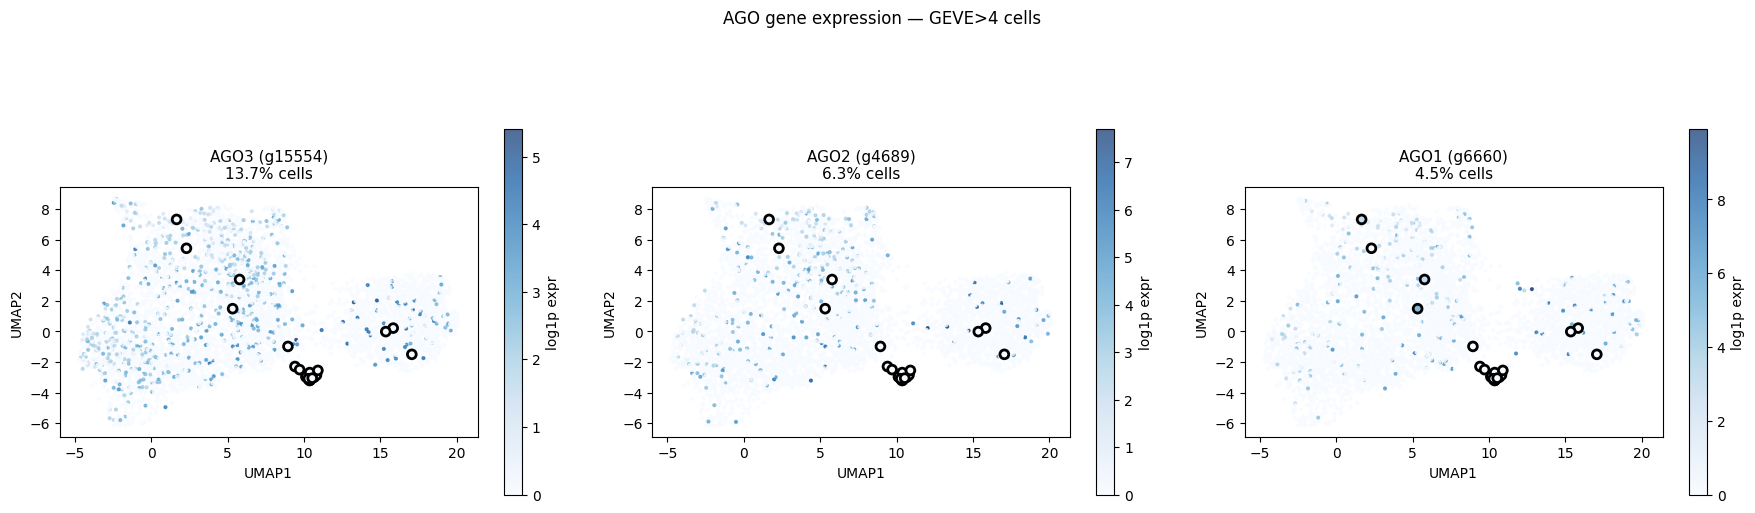

In [8]:
fig, axes = plt.subplots(1, len(ago_idx), figsize=(6 * len(ago_idx), 5.5))
if len(ago_idx) == 1:
    axes = [axes]

MCP_LW, MCP_S = 2.0, 40
cmap_ago = plt.cm.Blues

for ax, (name, expr) in zip(axes, ago_expr.items()):
    vmax = max(expr.max(), 0.1)
    norm = mcolors.Normalize(vmin=0, vmax=vmax)
    sc_a = ax.scatter(umap_hi[:,0], umap_hi[:,1], s=4, c=expr,
                       cmap=cmap_ago, norm=norm, alpha=0.7, rasterized=True)
    mcp_fc = cmap_ago(norm(expr[mcp_hi]))
    ax.scatter(umap_hi[mcp_hi,0], umap_hi[mcp_hi,1], s=MCP_S, alpha=1.0,
               facecolors=mcp_fc, edgecolors='black', linewidths=MCP_LW,
               zorder=8, rasterized=False)
    plt.colorbar(sc_a, ax=ax, label='log1p expr', shrink=0.75)
    pct = (expr > 0).mean() * 100
    ax.set_title(f'{name} ({AGO_GENES[name]})\n{pct:.1f}% cells', fontsize=11)
    ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2'); ax.set_aspect('equal')

plt.suptitle('AGO gene expression — GEVE>4 cells', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'ago_expression_umap.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'ago_expression_umap.pdf', bbox_inches='tight')
plt.show()

## Figure 3.4 — Doublet score on GEVE>4 UMAP

Scrublet doublet scores (computed in `upstream/01_QC.ipynb`) projected onto the GEVE>4 UMAP.  
High-score cells (predicted doublets) cluster together or appear at cluster boundaries.  
Cells with `predicted_doublet=True` shown with bold red border.

**Source**: `upstream/03_clustering.ipynb`  
**File**: `upstream/figures/doublet_score_umap.png`

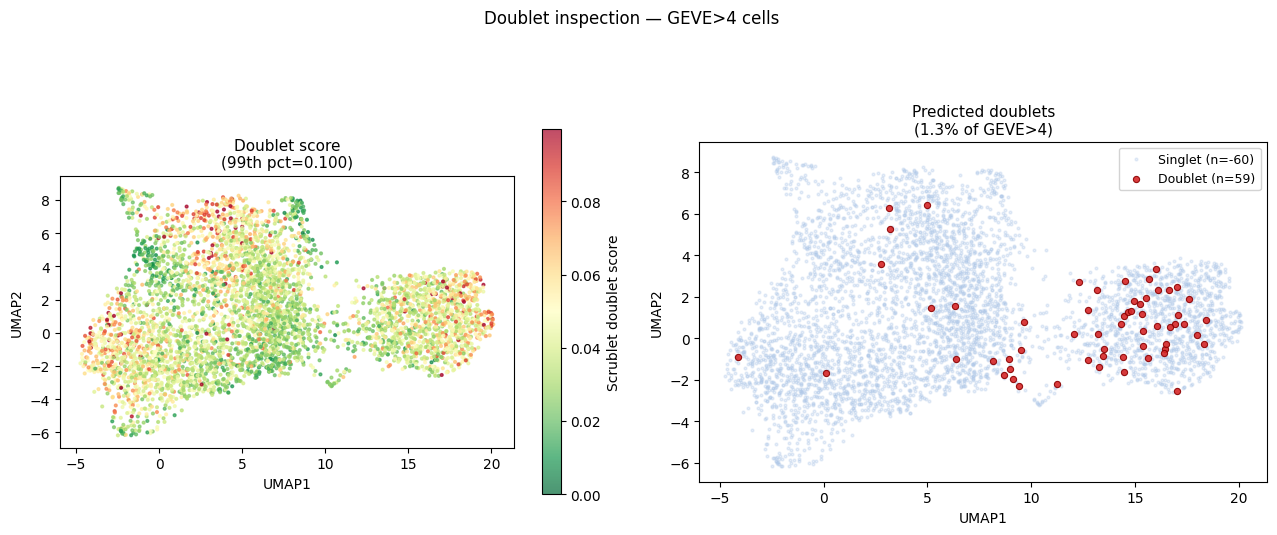

In [9]:
MCP_LW, MCP_S = 2.0, 40

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Panel A — continuous doublet score
ax = axes[0]
if 'doublet_score' in obs_hi.columns:
    dscore = obs_hi['doublet_score'].values.astype(float)
    vmax_d = np.percentile(dscore, 99)
    norm_d = mcolors.Normalize(vmin=0, vmax=vmax_d)
    sc_d = ax.scatter(umap_hi[:,0], umap_hi[:,1], s=4,
                       c=dscore, cmap='RdYlGn_r', norm=norm_d,
                       alpha=0.7, rasterized=True)
    plt.colorbar(sc_d, ax=ax, label='Scrublet doublet score', shrink=0.75)
    ax.set_title(f'Doublet score\n(99th pct={vmax_d:.3f})', fontsize=11)
else:
    ax.text(0.5, 0.5, 'doublet_score not found\nin adata.obs',
            ha='center', va='center', transform=ax.transAxes, fontsize=12)
    ax.set_title('Doublet score (missing)', fontsize=11)
ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2'); ax.set_aspect('equal')

# Panel B — predicted doublets
ax = axes[1]
if 'predicted_doublet' in obs_hi.columns:
    is_dbl = obs_hi['predicted_doublet'].values.astype(bool)
    ax.scatter(umap_hi[~is_dbl,0], umap_hi[~is_dbl,1], s=4, alpha=0.3,
               color='#aec7e8', rasterized=True, label=f'Singlet (n={~is_dbl.sum():,})')
    ax.scatter(umap_hi[is_dbl,0], umap_hi[is_dbl,1], s=20, alpha=0.9,
               color='#d62728', edgecolors='darkred', linewidths=0.8,
               zorder=5, rasterized=False, label=f'Doublet (n={is_dbl.sum():,})')
    ax.legend(fontsize=9, framealpha=0.85)
    ax.set_title(f'Predicted doublets\n({is_dbl.mean()*100:.1f}% of GEVE>4)', fontsize=11)
else:
    ax.text(0.5, 0.5, 'predicted_doublet not found\nin adata.obs',
            ha='center', va='center', transform=ax.transAxes, fontsize=12)
    ax.set_title('Predicted doublets (missing)', fontsize=11)
ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2'); ax.set_aspect('equal')

plt.suptitle('Doublet inspection — GEVE>4 cells', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'doublet_score_umap.png', dpi=150, bbox_inches='tight')
plt.savefig(FIG_DIR / 'doublet_score_umap.pdf', bbox_inches='tight')
plt.show()

## Figure 3.5 — Batch effect assessment (sample × DPI mixing)

Check whether the GEVE>4 UMAP separates cells by biological replicate (sample) rather than true biology.  
Each *Chlamydomonas* sample (s1A, s1B, s2A … s4B) corresponds to one DPI and one replicate.  
Good mixing within DPI groups indicates UMAP structure is driven by expression, not batch.

**Source**: `upstream/03_clustering.ipynb`  
**File**: `upstream/figures/batch_sample_umap.png`

In [10]:
# Derive sample labels from obs (sample column expected from split-pipe output)
if 'sample' in obs_hi.columns:
    samples = obs_hi['sample'].values
    sample_list = sorted(obs_hi['sample'].unique())
else:
    # Fall back to cell barcode suffix or dpi+replicate
    print("'sample' column not found — checking available obs columns:")
    print(obs_hi.columns.tolist())
    sample_list = []
    samples = np.array(['unknown'] * len(obs_hi))

print(f"Samples: {sample_list}")
if len(sample_list):
    print(obs_hi['sample'].value_counts().to_string())

Samples: ['s1A', 's1B', 's2A', 's2B', 's3A', 's3B', 's4A', 's4B']
sample
s4B    1955
s4A    1455
s2B     295
s3A     292
s2A     279
s3B     278
s1B      79
s1A      55


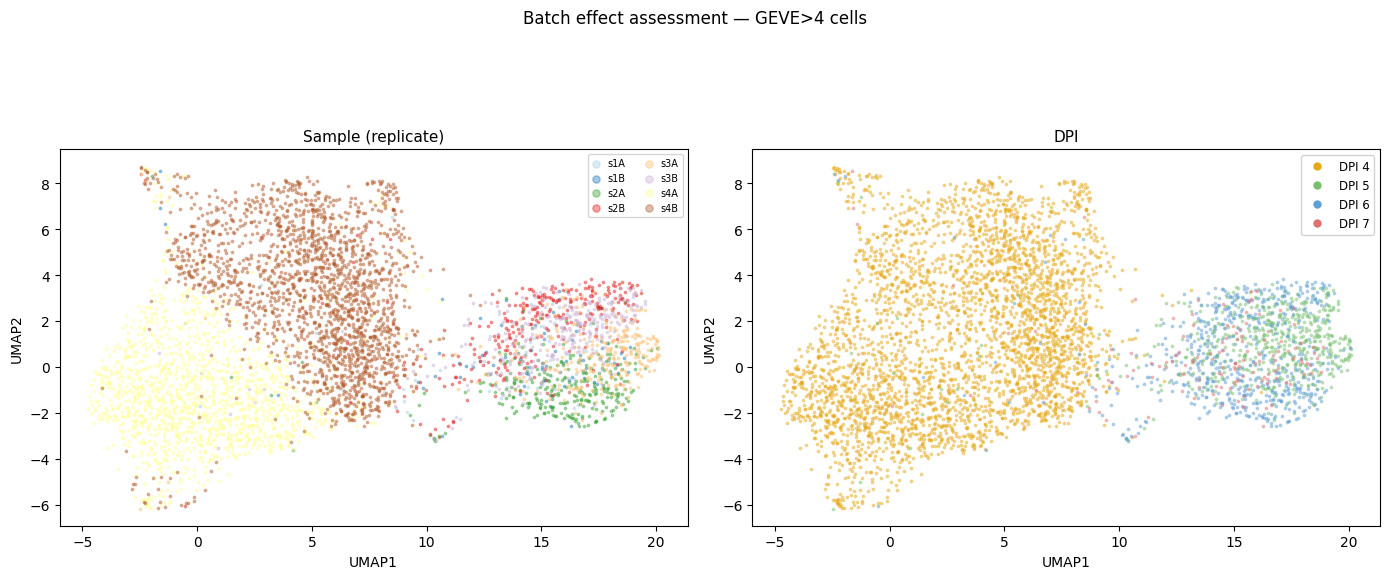

In [11]:
DPI_COLORS = {4: '#e6a817', 5: '#78c070', 6: '#5e9fd4', 7: '#e07070'}
MCP_LW, MCP_S = 2.0, 40

if len(sample_list) == 0:
    print("No sample information available — skipping batch plot.")
else:
    palette_s = plt.cm.Paired(np.linspace(0, 1, len(sample_list)))
    SAMPLE_COLORS = {s: palette_s[i] for i, s in enumerate(sample_list)}

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Panel A — coloured by sample (replicate)
    ax = axes[0]
    for s in sample_list:
        m = samples == s
        ax.scatter(umap_hi[m,0], umap_hi[m,1], s=3, alpha=0.4,
                   color=SAMPLE_COLORS[s], rasterized=True, label=s)
    ax.legend(fontsize=7, loc='best', framealpha=0.8, markerscale=3,
              ncol=2, handlelength=0.8)
    ax.set_title('Sample (replicate)', fontsize=11)
    ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2'); ax.set_aspect('equal')

    # Panel B — coloured by DPI
    ax = axes[1]
    for dpi in [4, 5, 6, 7]:
        m = (obs_hi['dpi'] == dpi).values
        ax.scatter(umap_hi[m,0], umap_hi[m,1], s=3, alpha=0.4,
                   color=DPI_COLORS[dpi], rasterized=True, label=f'DPI {dpi}')
    handles = [mlines.Line2D([], [], marker='o', color='w',
               markerfacecolor=DPI_COLORS[d], markersize=7, label=f'DPI {d}')
               for d in [4,5,6,7]]
    ax.legend(handles=handles, fontsize=8.5, loc='best', framealpha=0.85)
    ax.set_title('DPI', fontsize=11)
    ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2'); ax.set_aspect('equal')

    plt.suptitle('Batch effect assessment — GEVE>4 cells', fontsize=12, y=1.02)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'batch_sample_umap.png', dpi=150, bbox_inches='tight')
    plt.savefig(FIG_DIR / 'batch_sample_umap.pdf', bbox_inches='tight')
    plt.show()

In [12]:
del adata_hi
gc.collect()
print("GEVE>4 adata freed.")

GEVE>4 adata freed.
